In [1]:
# ============ CELL 0: Environment setup ============
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from itertools import product
import warnings; warnings.filterwarnings("ignore")

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
PAL = {"blue":"#2563eb","teal":"#0d9488","amber":"#d97706","red":"#dc2626",
       "violet":"#7c3aed","grey":"#64748b","green":"#16a34a"}
print("PaySphere SOA simulation environment ready | seed =", SEED)

PaySphere SOA simulation environment ready | seed = 42


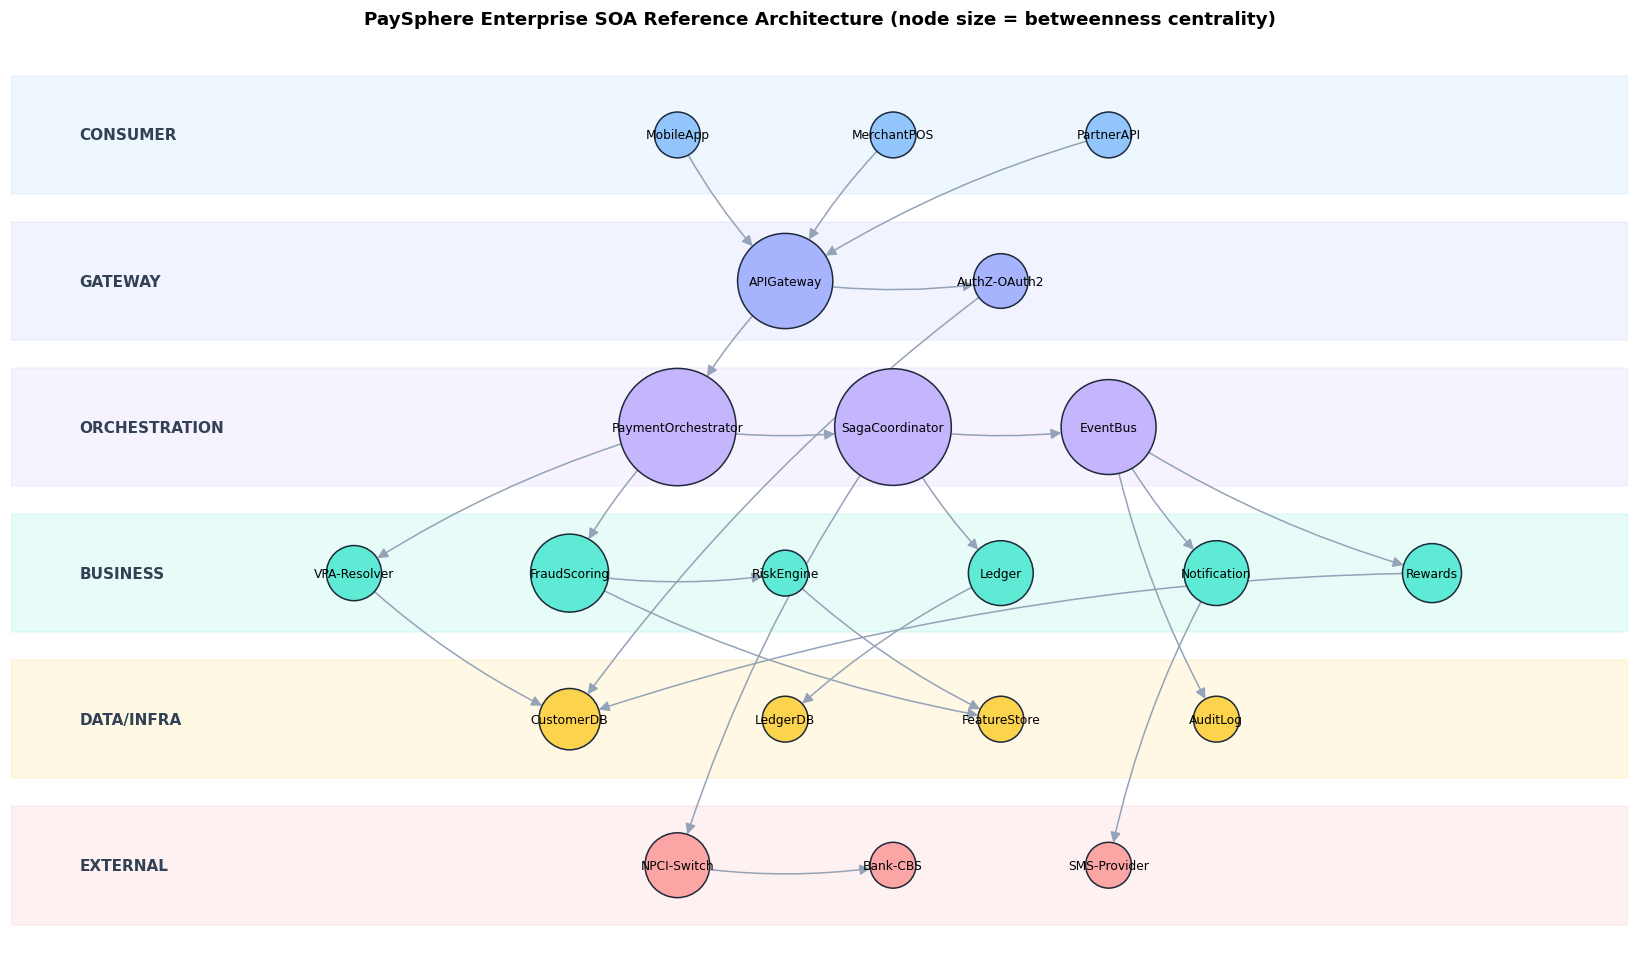

Service inventory (top 8 by structural criticality):


,service,layer,fan_in,fan_out,betweenness
0,PaymentOrchestrator,Orchestration,1,3,0.555
1,SagaCoordinator,Orchestration,1,3,0.547
2,APIGateway,Gateway,3,2,0.332
3,EventBus,Orchestration,1,3,0.329
4,FraudScoring,Business,1,2,0.189
5,Notification,Business,1,1,0.100
6,Ledger,Business,1,1,0.100
7,NPCI-Switch,External,1,1,0.100


In [2]:
# ============ CELL 1: Build the layered service inventory ============
LAYERS = {
    "Consumer":     ["MobileApp", "MerchantPOS", "PartnerAPI"],
    "Gateway":      ["APIGateway", "AuthZ-OAuth2"],
    "Orchestration":["PaymentOrchestrator", "SagaCoordinator", "EventBus"],
    "Business":     ["VPA-Resolver", "FraudScoring", "RiskEngine", "Ledger", "Notification", "Rewards"],
    "Data/Infra":   ["CustomerDB", "LedgerDB", "FeatureStore", "AuditLog"],
    "External":     ["NPCI-Switch", "Bank-CBS", "SMS-Provider"],
}
EDGES = [
 ("MobileApp","APIGateway"),("MerchantPOS","APIGateway"),("PartnerAPI","APIGateway"),
 ("APIGateway","AuthZ-OAuth2"),("APIGateway","PaymentOrchestrator"),
 ("PaymentOrchestrator","VPA-Resolver"),("PaymentOrchestrator","FraudScoring"),
 ("PaymentOrchestrator","SagaCoordinator"),("SagaCoordinator","Ledger"),
 ("SagaCoordinator","NPCI-Switch"),("NPCI-Switch","Bank-CBS"),
 ("FraudScoring","RiskEngine"),("FraudScoring","FeatureStore"),("RiskEngine","FeatureStore"),
 ("VPA-Resolver","CustomerDB"),("Ledger","LedgerDB"),
 ("SagaCoordinator","EventBus"),("EventBus","Notification"),("EventBus","Rewards"),
 ("EventBus","AuditLog"),("Notification","SMS-Provider"),("Rewards","CustomerDB"),
 ("AuthZ-OAuth2","CustomerDB"),
]
G = nx.DiGraph()
for layer, svcs in LAYERS.items():
    for s in svcs: G.add_node(s, layer=layer)
G.add_edges_from(EDGES)

# Layered layout
pos, layer_names = {}, list(LAYERS)
for li, layer in enumerate(layer_names):
    svcs = LAYERS[layer]
    for i, s in enumerate(svcs):
        pos[s] = ((i - (len(svcs)-1)/2) * 2.2, -li * 1.6)

lcol = dict(zip(layer_names, ["#93c5fd","#a5b4fc","#c4b5fd","#5eead4","#fcd34d","#fca5a5"]))
btw = nx.betweenness_centrality(G.to_undirected())
sizes = [900 + 9000*btw[n] for n in G]

fig, ax = plt.subplots(figsize=(15, 9))
for li, layer in enumerate(layer_names):
    ax.axhspan(-li*1.6-0.65, -li*1.6+0.65, color=lcol[layer], alpha=0.15, zorder=0)
    ax.text(-8.3, -li*1.6, layer.upper(), fontsize=10, fontweight="bold", va="center", color="#334155")
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#94a3b8", arrows=True, arrowsize=14,
                       connectionstyle="arc3,rad=0.08", node_size=sizes)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes,
                       node_color=[lcol[G.nodes[n]["layer"]] for n in G], edgecolors="#1e293b")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
ax.set_title("PaySphere Enterprise SOA Reference Architecture (node size = betweenness centrality)")
ax.set_xlim(-9, 7.5); ax.axis("off"); plt.tight_layout(); plt.show()

inv = pd.DataFrame({"service": list(G), "layer": [G.nodes[n]["layer"] for n in G],
                    "fan_in": [G.in_degree(n) for n in G], "fan_out": [G.out_degree(n) for n in G],
                    "betweenness": [round(btw[n],3) for n in G]}).sort_values("betweenness", ascending=False)
print("Service inventory (top 8 by structural criticality):")
display(inv.head(8).reset_index(drop=True))

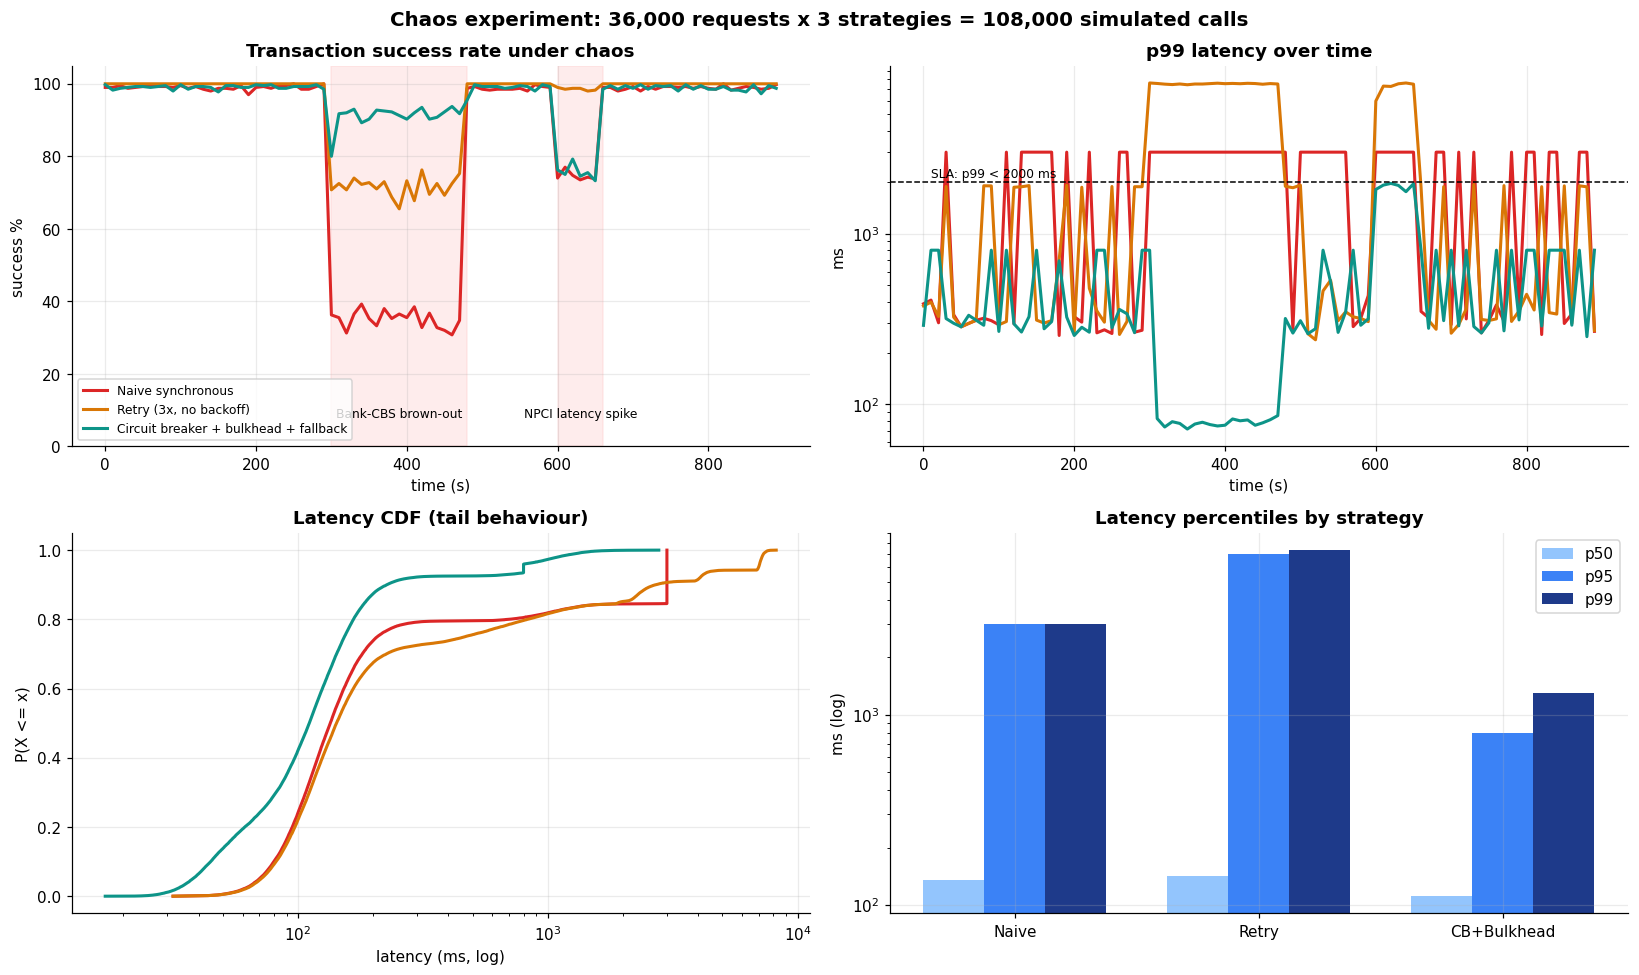

,success,p50,p95,p99
strategy,,,,
Naive synchronous,84.52 %,134.7,3000.0,3000.0
"Retry (3x, no backoff)",94.21 %,142.6,6980.1,7321.0
Circuit breaker + bulkhead + fallback,95.84 %,111.0,800.0,1292.1


In [3]:
# ============ CELL 2: Discrete-event simulation of 3 resilience strategies ============
T, RPS = 900, 40                       # 900 s of traffic at 40 req/s = 36,000 requests
N = T * RPS
t = np.repeat(np.arange(T), RPS) + rng.random(N)

# Chaos schedule: Bank-CBS brown-out (300-480s), NPCI latency spike (600-660s)
def fault_prob(ts):
    p = np.full_like(ts, 0.01)
    p[(ts>=300)&(ts<480)] = 0.65
    p[(ts>=600)&(ts<660)] = 0.25
    return p
base_lat = rng.lognormal(mean=np.log(120), sigma=0.35, size=N)   # ms
spike = np.where((t>=600)&(t<660), rng.lognormal(np.log(900),0.3,N), 0)

def simulate(strategy):
    lat, ok = base_lat + spike, np.ones(N, bool)
    p_fail = fault_prob(t)
    if strategy == "Naive synchronous":
        fail = rng.random(N) < p_fail
        lat = np.where(fail, 3000, lat)            # waits for full timeout
        ok = ~fail
    elif strategy == "Retry (3x, no backoff)":
        attempts_fail = rng.random((N,3)) < p_fail[:,None]
        n_tries = np.where(attempts_fail.all(1), 3, attempts_fail.argmin(1)+1)
        ok = ~attempts_fail.all(1)
        lat = lat + (n_tries-1)*3000*0.6 + np.where(ok,0,3000)
        # retry storm: amplified load degrades latency for everyone during fault
        storm = ((t>=300)&(t<480)) * rng.lognormal(np.log(400),0.4,N)
        lat = lat + storm
    else:  # Circuit breaker + bulkhead + cached fallback
        fail = rng.random(N) < p_fail
        window_err = pd.Series(fail.astype(float)).rolling(200, min_periods=1).mean().values
        open_ = window_err > 0.30
        fallback_ok = rng.random(N) < 0.92          # degraded-mode acceptance (deferred settlement)
        ok = np.where(open_, fallback_ok, ~fail)
        lat = np.where(open_, rng.lognormal(np.log(45),0.25,N), np.where(fail, 800, lat))
    return pd.DataFrame({"t": t, "latency": lat, "ok": ok, "strategy": strategy})

strategies = ["Naive synchronous", "Retry (3x, no backoff)", "Circuit breaker + bulkhead + fallback"]
SIM = pd.concat([simulate(s) for s in strategies], ignore_index=True)
cols = [PAL["red"], PAL["amber"], PAL["teal"]]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
ax = axes[0,0]
for s,c in zip(strategies, cols):
    d = SIM[SIM.strategy==s].groupby(SIM.t.astype(int)//10).ok.mean()*100
    ax.plot(d.index*10, d.values, color=c, lw=2, label=s)
for a,b,lbl in [(300,480,"Bank-CBS brown-out"),(600,660,"NPCI latency spike")]:
    ax.axvspan(a,b,color="#fecaca",alpha=0.35); ax.text((a+b)/2, 8, lbl, ha="center", fontsize=8)
ax.set(title="Transaction success rate under chaos", xlabel="time (s)", ylabel="success %", ylim=(0,105))
ax.legend(fontsize=8, loc="lower left")

ax = axes[0,1]
for s,c in zip(strategies, cols):
    d = SIM[SIM.strategy==s].groupby(SIM.t.astype(int)//10).latency.quantile(0.99)
    ax.plot(d.index*10, d.values, color=c, lw=2, label=s)
ax.axhline(2000, ls="--", color="k", lw=1); ax.text(10, 2150, "SLA: p99 < 2000 ms", fontsize=8)
ax.set(title="p99 latency over time", xlabel="time (s)", ylabel="ms", yscale="log")

ax = axes[1,0]
for s,c in zip(strategies, cols):
    x = np.sort(SIM[SIM.strategy==s].latency.values)
    ax.plot(x, np.linspace(0,1,len(x)), color=c, lw=2, label=s)
ax.set(title="Latency CDF (tail behaviour)", xlabel="latency (ms, log)", ylabel="P(X <= x)", xscale="log")

ax = axes[1,1]
summ = SIM.groupby("strategy").agg(success=("ok","mean"), p50=("latency","median"),
        p95=("latency",lambda x: x.quantile(.95)), p99=("latency",lambda x: x.quantile(.99))).loc[strategies]
x = np.arange(3); w=0.25
for i,(q,c) in enumerate(zip(["p50","p95","p99"],["#93c5fd","#3b82f6","#1e3a8a"])):
    ax.bar(x+(i-1)*w, summ[q], w, color=c, label=q)
ax.set_xticks(x); ax.set_xticklabels(["Naive","Retry","CB+Bulkhead"]); ax.set_yscale("log")
ax.set(title="Latency percentiles by strategy", ylabel="ms (log)"); ax.legend()
plt.suptitle(f"Chaos experiment: {N:,} requests x 3 strategies = {3*N:,} simulated calls", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

summ["success"] = (summ.success*100).round(2).astype(str)+" %"
display(summ.round(1))

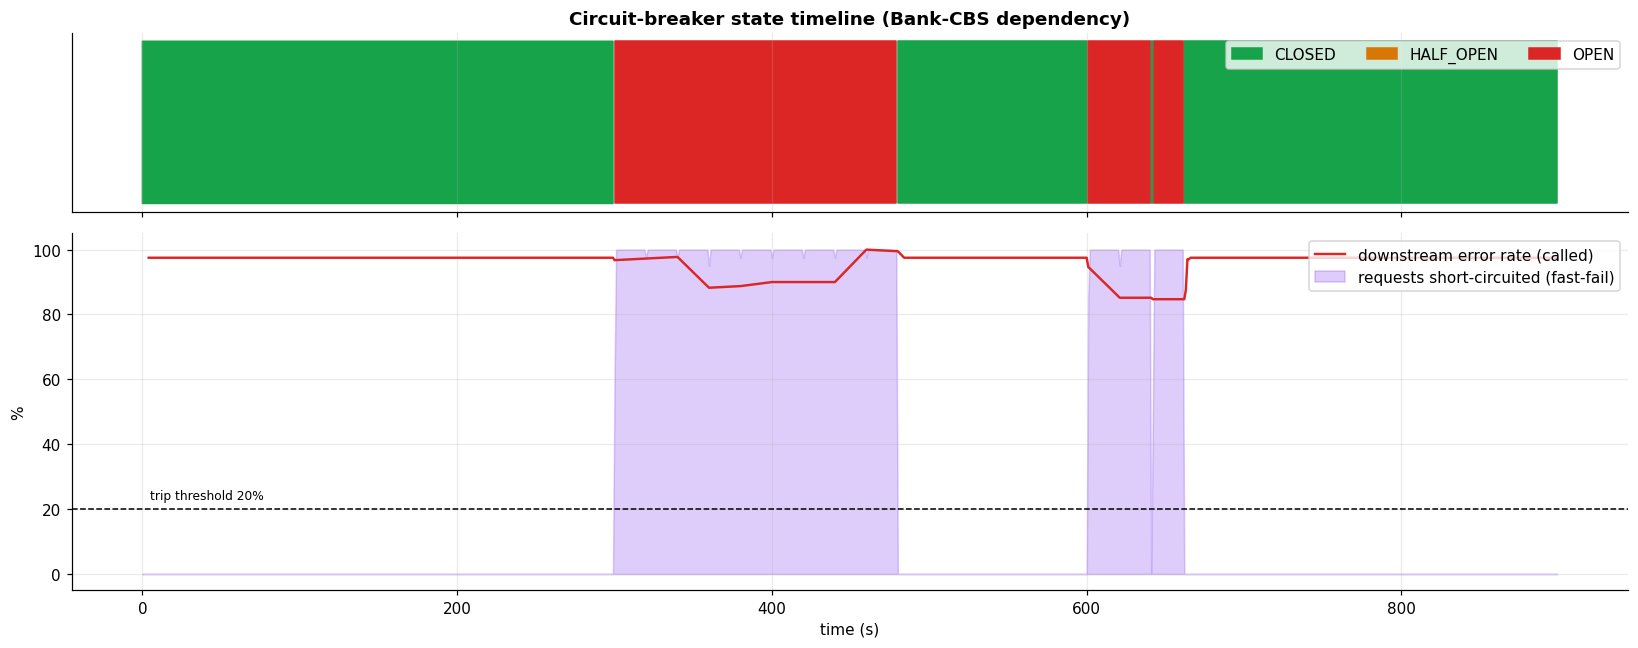

State transitions: 6 | calls shielded from failing dependency: 9,546


In [4]:
2# ============ CELL 3: Explicit circuit-breaker finite state machine ============
class CircuitBreaker:
    def __init__(self, fail_threshold=0.2, window=50, open_timeout=20, half_open_probes=10):
        self.state, self.window, self.thr = "CLOSED", window, fail_threshold
        self.open_timeout, self.probes = open_timeout, half_open_probes
        self.buf, self.opened_at, self.probe_res = [], None, []
    def allow(self, now):
        if self.state == "OPEN" and now - self.opened_at >= self.open_timeout:
            self.state, self.probe_res = "HALF_OPEN", []
        return self.state != "OPEN"
    def record(self, success, now):
        if self.state == "HALF_OPEN":
            self.probe_res.append(success)
            if not success: self.state, self.opened_at = "OPEN", now
            elif len(self.probe_res) >= self.probes: self.state, self.buf = "CLOSED", []
            return
        self.buf = (self.buf + [success])[-self.window:]
        if len(self.buf) == self.window and 1 - np.mean(self.buf) > self.thr:
            self.state, self.opened_at = "OPEN", now

cb, log = CircuitBreaker(), []
for sec in range(T):
    p = fault_prob(np.array([float(sec)]))[0]
    for _ in range(RPS):
        if cb.allow(sec):
            s = rng.random() > p; cb.record(s, sec); log.append((sec, cb.state, s, "called"))
        else:
            log.append((sec, cb.state, None, "short-circuited"))
L = pd.DataFrame(log, columns=["t","state","success","action"])

smap = {"CLOSED":0,"HALF_OPEN":1,"OPEN":2}; scol = {"CLOSED":PAL["green"],"HALF_OPEN":PAL["amber"],"OPEN":PAL["red"]}
st = L.groupby("t").state.agg(lambda x: x.mode()[0])
fig, (a1,a2) = plt.subplots(2,1, figsize=(15,6), sharex=True, gridspec_kw={"height_ratios":[1,2]})
for sname,c in scol.items():
    m = (st==sname).values
    a1.fill_between(st.index, 0, 1, where=m, color=c, step="mid", label=sname)
a1.set_yticks([]); a1.set_title("Circuit-breaker state timeline (Bank-CBS dependency)"); a1.legend(ncol=3, loc="upper right")
err = L[L.action=="called"].groupby("t").success.apply(lambda x: 1-x.mean())
sc = L.groupby("t").action.apply(lambda x: (x=="short-circuited").mean())
a2.plot(err.index, err.rolling(5).mean()*100, color=PAL["red"], lw=1.6, label="downstream error rate (called)")
a2.fill_between(sc.index, sc*100, color=PAL["violet"], alpha=0.25, label="requests short-circuited (fast-fail)")
a2.axhline(20, ls="--", color="k", lw=1); a2.text(5,23,"trip threshold 20%",fontsize=8)
a2.set(xlabel="time (s)", ylabel="%"); a2.legend(loc="upper right"); plt.tight_layout(); plt.show()

trans = (st != st.shift()).sum()-1
print(f"State transitions: {trans} | calls shielded from failing dependency: {(L.action=='short-circuited').sum():,}")

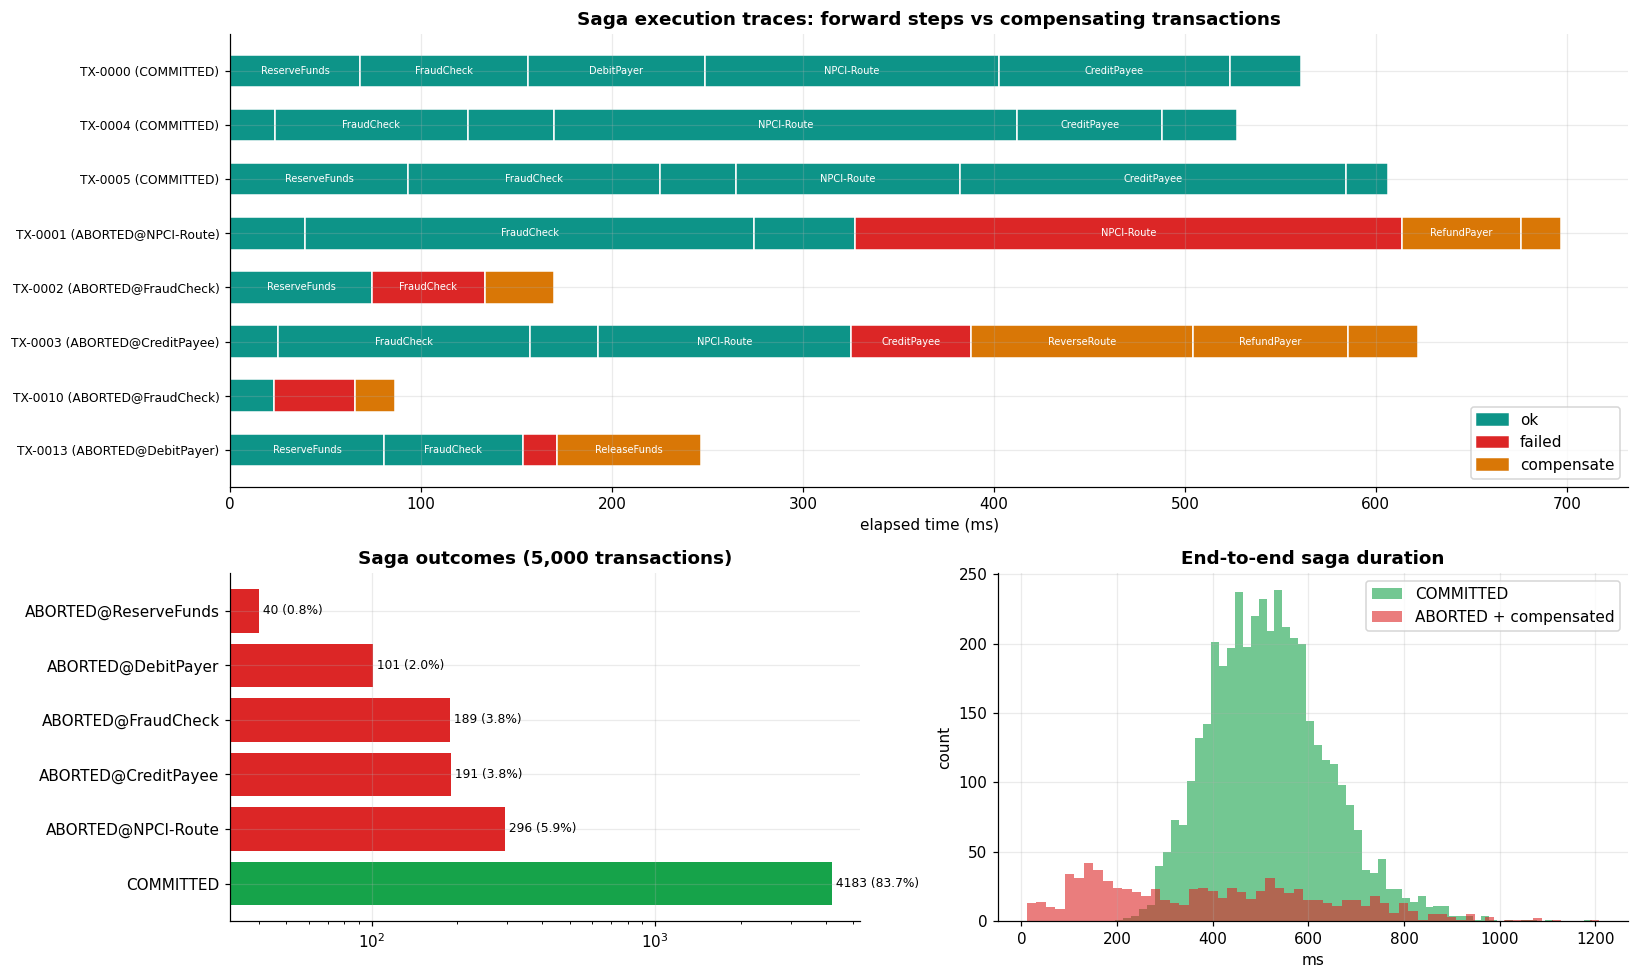

Consistency guarantee: 5000 sagas, 0 left in a partial state; 817 rolled back via 1455 compensations


In [5]:
# ============ CELL 4: Orchestrated saga for a P2P payment ============
STEPS = [("ReserveFunds","ReleaseFunds"),("FraudCheck",None),("DebitPayer","RefundPayer"),
         ("NPCI-Route","ReverseRoute"),("CreditPayee","ReverseCredit"),("Notify",None)]
FAILP = {"ReserveFunds":0.01,"FraudCheck":0.04,"DebitPayer":0.02,"NPCI-Route":0.06,"CreditPayee":0.05,"Notify":0.0}
DUR   = {"ReserveFunds":40,"FraudCheck":90,"DebitPayer":60,"NPCI-Route":180,"CreditPayee":120,"Notify":30}

def run_saga(txid):
    clock, events, done = 0.0, [], []
    for fwd, comp in STEPS:
        d = rng.gamma(4, DUR[fwd]/4)
        if rng.random() < FAILP[fwd]:
            events.append((txid, fwd, clock, d, "failed")); clock += d
            for f, c in reversed(done):
                if c:
                    cd = rng.gamma(4, DUR[f]/5)
                    events.append((txid, c, clock, cd, "compensate")); clock += cd
            return events, f"ABORTED@{fwd}", clock
        events.append((txid, fwd, clock, d, "ok")); clock += d; done.append((fwd, comp))
    return events, "COMMITTED", clock

all_ev, outcomes = [], []
for i in range(5000):
    ev, out, dur = run_saga(i); all_ev += ev; outcomes.append((i, out, dur, len(ev)))
O = pd.DataFrame(outcomes, columns=["tx","outcome","duration_ms","steps"])
E = pd.DataFrame(all_ev, columns=["tx","step","start","dur","kind"])

fig = plt.figure(figsize=(15,9)); gs = fig.add_gridspec(2,2, height_ratios=[1.3,1])
ax = fig.add_subplot(gs[0,:])
sample = list(O[O.outcome=="COMMITTED"].tx[:3]) + list(O[O.outcome!="COMMITTED"].tx[:5])
kc = {"ok":PAL["teal"],"failed":PAL["red"],"compensate":PAL["amber"]}
for row, tx in enumerate(sample):
    for _, e in E[E.tx==tx].iterrows():
        ax.barh(row, e.dur, left=e.start, color=kc[e.kind], edgecolor="white", height=0.6)
        if e.dur > 55: ax.text(e.start+e.dur/2, row, e.step, ha="center", va="center", fontsize=6.5, color="white")
ax.set_yticks(range(len(sample))); ax.set_yticklabels([f"TX-{tx:04d} ({O.outcome[tx]})" for tx in sample], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("elapsed time (ms)"); ax.set_title("Saga execution traces: forward steps vs compensating transactions")
ax.legend(handles=[mpatches.Patch(color=v,label=k) for k,v in kc.items()], loc="lower right")

ax = fig.add_subplot(gs[1,0])
oc = O.outcome.value_counts()
ax.barh(oc.index, oc.values, color=[PAL["green"] if k=="COMMITTED" else PAL["red"] for k in oc.index])
for i,v in enumerate(oc.values): ax.text(v, i, f" {v} ({v/len(O):.1%})", va="center", fontsize=8)
ax.set_title("Saga outcomes (5,000 transactions)"); ax.set_xscale("log")

ax = fig.add_subplot(gs[1,1])
for k,c in [("COMMITTED",PAL["green"])]:
    ax.hist(O[O.outcome==k].duration_ms, bins=60, alpha=0.6, color=c, label=k)
ax.hist(O[O.outcome!="COMMITTED"].duration_ms, bins=60, alpha=0.6, color=PAL["red"], label="ABORTED + compensated")
ax.set(title="End-to-end saga duration", xlabel="ms", ylabel="count"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Consistency guarantee: {len(O)} sagas, 0 left in a partial state; "
      f"{(O.outcome!='COMMITTED').sum()} rolled back via {(E.kind=='compensate').sum()} compensations")

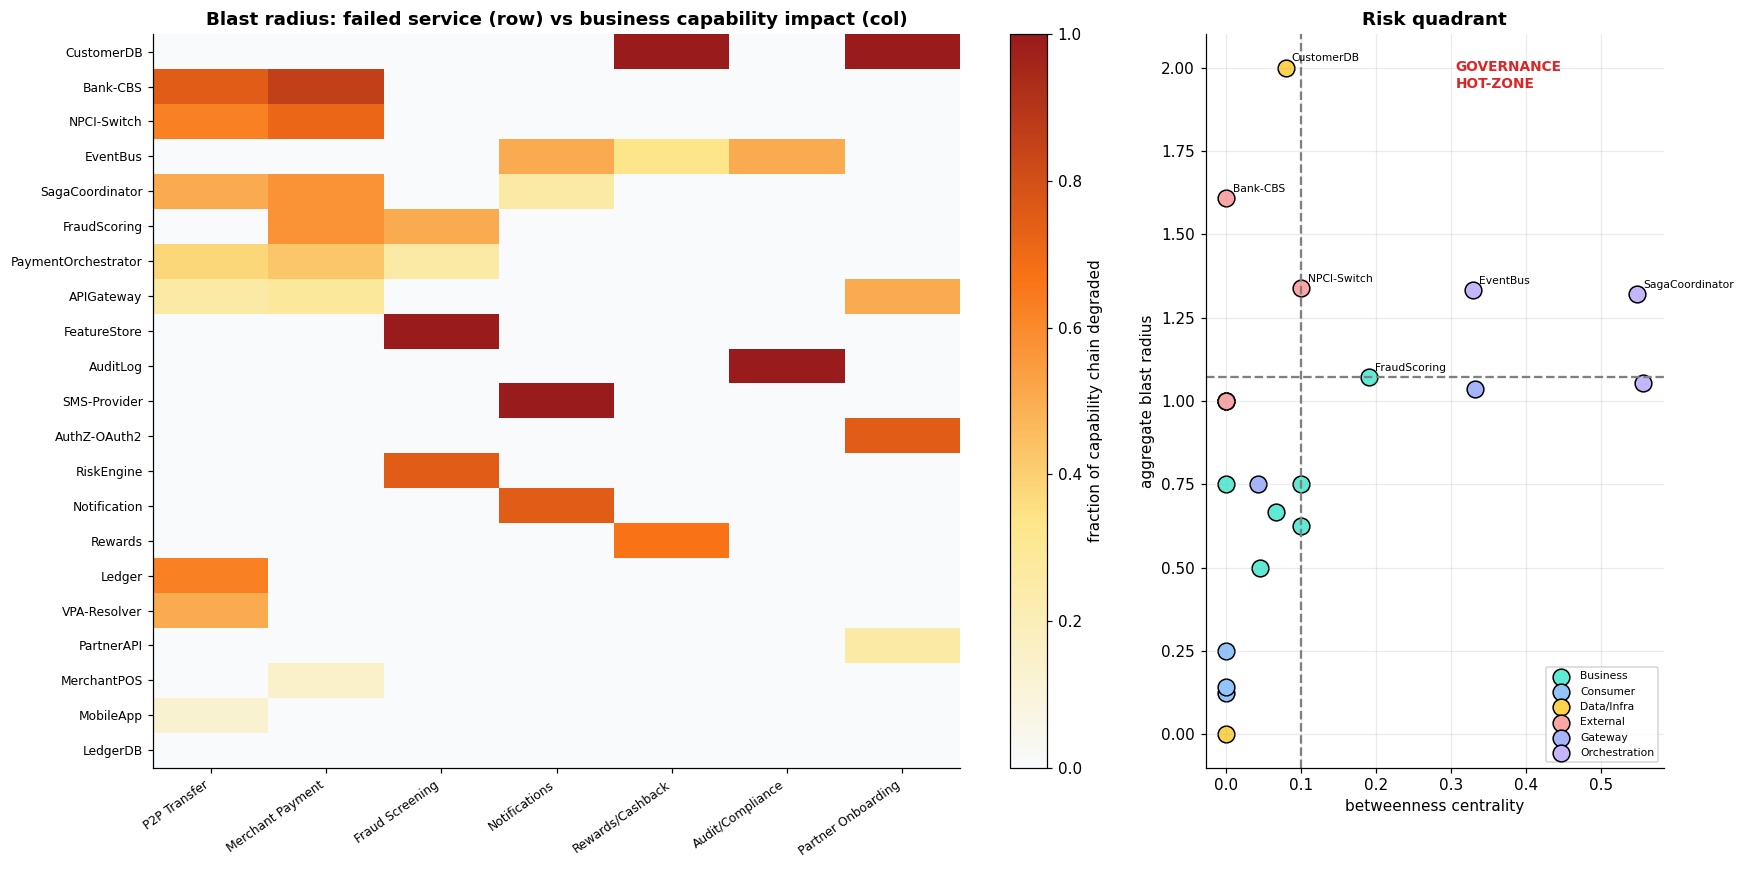

,service,blast,btw,layer
0,CustomerDB,2.000,0.079,Data/Infra
1,Bank-CBS,1.607,0.000,External
2,NPCI-Switch,1.339,0.100,External
3,EventBus,1.333,0.329,Orchestration
4,SagaCoordinator,1.321,0.547,Orchestration
5,FraudScoring,1.071,0.189,Business


In [6]:
# ============ CELL 5: Single-point-of-failure / cascading impact matrix ============
CAPABILITIES = {
    "P2P Transfer":     ["MobileApp","APIGateway","PaymentOrchestrator","VPA-Resolver","SagaCoordinator","NPCI-Switch","Bank-CBS","Ledger"],
    "Merchant Payment": ["MerchantPOS","APIGateway","PaymentOrchestrator","FraudScoring","SagaCoordinator","NPCI-Switch","Bank-CBS"],
    "Fraud Screening":  ["PaymentOrchestrator","FraudScoring","RiskEngine","FeatureStore"],
    "Notifications":    ["SagaCoordinator","EventBus","Notification","SMS-Provider"],
    "Rewards/Cashback": ["EventBus","Rewards","CustomerDB"],
    "Audit/Compliance": ["EventBus","AuditLog"],
    "Partner Onboarding":["PartnerAPI","APIGateway","AuthZ-OAuth2","CustomerDB"],
}
svcs = list(G)
# A failure propagates upstream: every caller in the capability's call chain that
# (transitively) depends on the failed service is degraded.
M = np.zeros((len(svcs), len(CAPABILITIES)))
for j, (cap, chain) in enumerate(CAPABILITIES.items()):
    H = G.subgraph(chain)
    for i, s in enumerate(svcs):
        if s in H:
            impacted = nx.ancestors(H, s) | {s}
            M[i,j] = len(impacted) / len(chain)
order = np.argsort(-M.sum(1))
cmap = LinearSegmentedColormap.from_list("br", ["#f8fafc","#fde68a","#f97316","#991b1b"])

fig, (a1,a2) = plt.subplots(1,2, figsize=(16,8), gridspec_kw={"width_ratios":[2.2,1]})
im = a1.imshow(M[order], cmap=cmap, aspect="auto", vmin=0, vmax=1)
a1.set_yticks(range(len(svcs))); a1.set_yticklabels(np.array(svcs)[order], fontsize=8)
a1.set_xticks(range(len(CAPABILITIES))); a1.set_xticklabels(CAPABILITIES, rotation=35, ha="right", fontsize=8)
a1.grid(False); a1.set_title("Blast radius: failed service (row) vs business capability impact (col)")
plt.colorbar(im, ax=a1, label="fraction of capability chain degraded")

risk = pd.DataFrame({"service":svcs, "blast":M.sum(1), "btw":[btw[s] for s in svcs],
                     "layer":[G.nodes[s]["layer"] for s in svcs]})
for lay, g in risk.groupby("layer"):
    a2.scatter(g.btw, g.blast, s=120, color=lcol[lay], edgecolor="k", label=lay)
for _, r in risk.nlargest(6,"blast").iterrows():
    a2.annotate(r.service, (r.btw, r.blast), fontsize=7, xytext=(4,4), textcoords="offset points")
a2.axhline(risk.blast.quantile(.75), ls="--", color="grey"); a2.axvline(risk.btw.quantile(.75), ls="--", color="grey")
a2.text(risk.btw.max()*0.55, risk.blast.max()*0.97, "GOVERNANCE\nHOT-ZONE", color=PAL["red"], fontweight="bold", fontsize=9)
a2.set(xlabel="betweenness centrality", ylabel="aggregate blast radius", title="Risk quadrant"); a2.legend(fontsize=7)
plt.tight_layout(); plt.show()
display(risk.sort_values("blast", ascending=False).head(6).round(3).reset_index(drop=True))

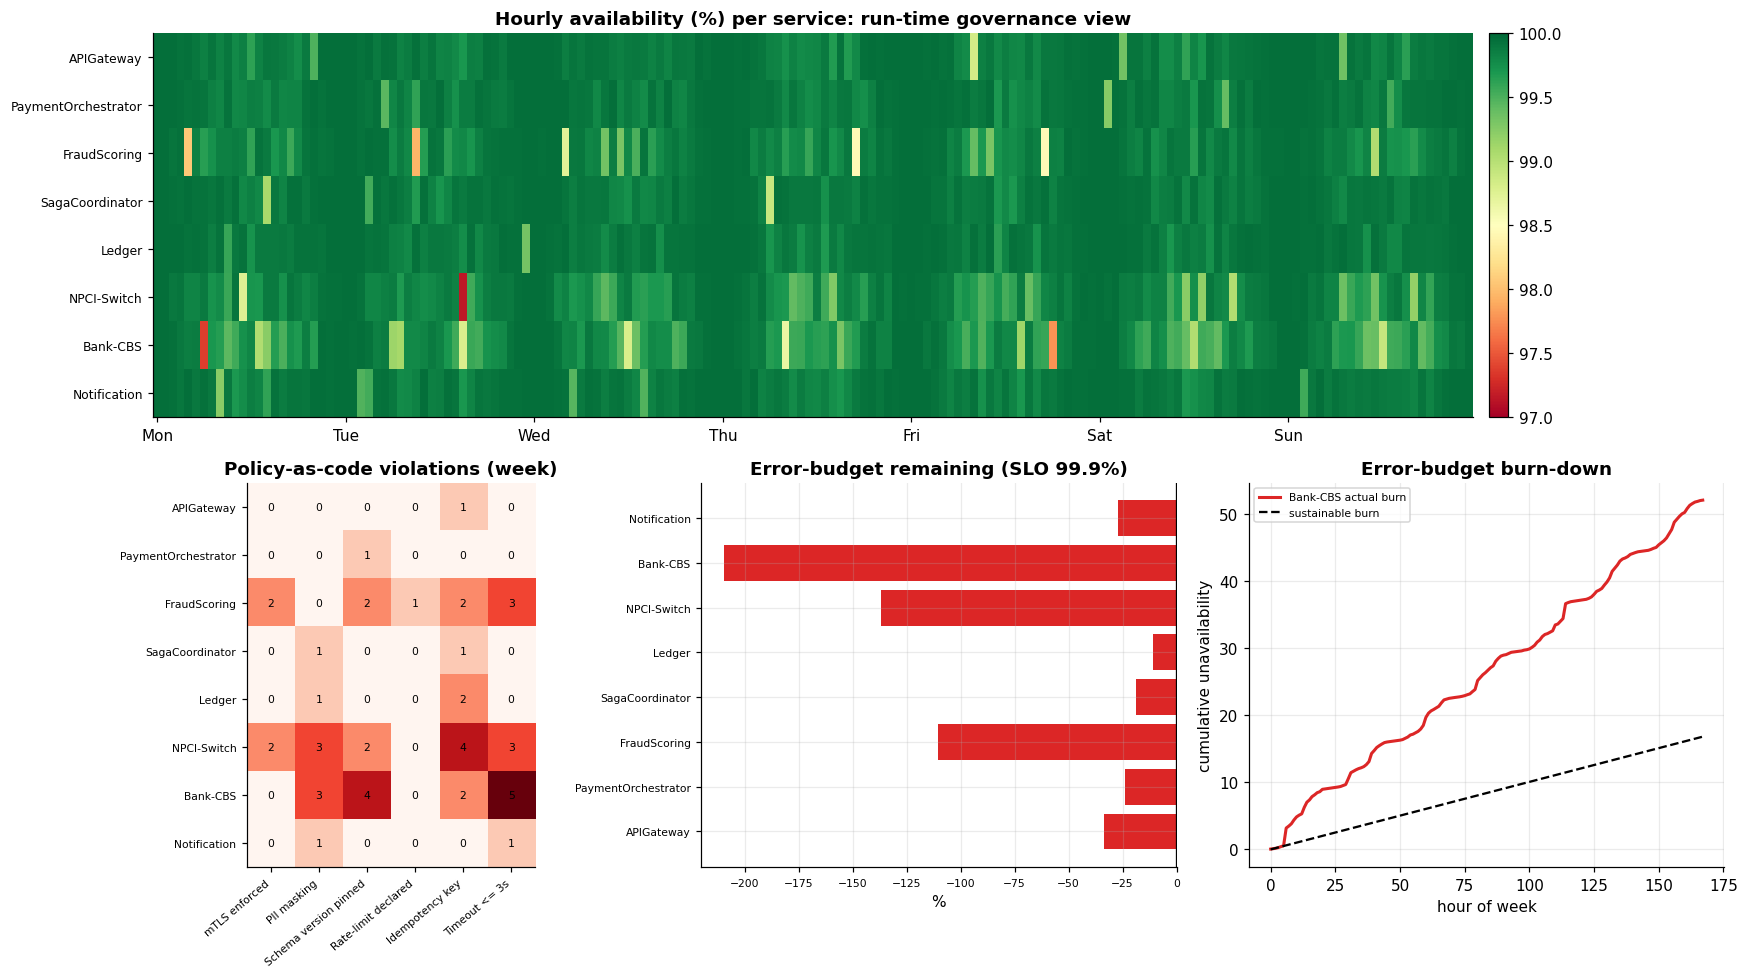

In [7]:
# ============ CELL 6: 7-day x 24-hour SLA compliance + policy-as-code violations ============
gov_svcs = ["APIGateway","PaymentOrchestrator","FraudScoring","SagaCoordinator","Ledger","NPCI-Switch","Bank-CBS","Notification"]
hours = 24*7
diurnal = 0.5 + 0.5*np.sin((np.arange(hours)%24 - 6)/24*2*np.pi)   # load curve peaks ~noon-evening
SLA = np.zeros((len(gov_svcs), hours))
for i, s in enumerate(gov_svcs):
    fragility = {"Bank-CBS":0.9,"NPCI-Switch":0.7,"FraudScoring":0.5}.get(s, 0.25)
    SLA[i] = 99.95 - fragility*diurnal*rng.gamma(2,0.25,hours) - (rng.random(hours)<0.02)*rng.uniform(1,4,hours)*fragility
SLA = np.clip(SLA, 94, 100)

POLICIES = ["mTLS enforced","PII masking","Schema version pinned","Rate-limit declared","Idempotency key","Timeout <= 3s"]
VIOL = rng.poisson(lam=np.outer([0.2,0.4,1.5,0.6,0.3,2.2,3.0,0.8], [0.3,1.0,0.8,0.5,1.4,0.9]))

fig = plt.figure(figsize=(16,9)); gs = fig.add_gridspec(2,3)
ax = fig.add_subplot(gs[0,:])
im = ax.imshow(SLA, aspect="auto", cmap="RdYlGn", vmin=97, vmax=100)
ax.set_yticks(range(len(gov_svcs))); ax.set_yticklabels(gov_svcs, fontsize=8); ax.grid(False)
ax.set_xticks(range(0,hours,24)); ax.set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_title("Hourly availability (%) per service: run-time governance view"); plt.colorbar(im, ax=ax, pad=0.01)

ax = fig.add_subplot(gs[1,0])
im = ax.imshow(VIOL, cmap="Reds"); ax.grid(False)
ax.set_xticks(range(len(POLICIES))); ax.set_xticklabels(POLICIES, rotation=40, ha="right", fontsize=7)
ax.set_yticks(range(len(gov_svcs))); ax.set_yticklabels(gov_svcs, fontsize=7)
for i in range(VIOL.shape[0]):
    for j in range(VIOL.shape[1]): ax.text(j,i,VIOL[i,j],ha="center",va="center",fontsize=7)
ax.set_title("Policy-as-code violations (week)")

ax = fig.add_subplot(gs[1,1])
slo, target = SLA.mean(1), 99.9
budget = (1 - (100-slo)/(100-target)) * 100
ax.barh(gov_svcs, budget, color=[PAL["green"] if b>25 else PAL["amber"] if b>0 else PAL["red"] for b in budget])
ax.axvline(0, color="k"); ax.set_title("Error-budget remaining (SLO 99.9%)"); ax.set_xlabel("%"); ax.tick_params(labelsize=7)

ax = fig.add_subplot(gs[1,2])
cum = np.cumsum(100 - SLA[gov_svcs.index("Bank-CBS")])
ax.plot(cum, color=PAL["red"], lw=2, label="Bank-CBS actual burn")
ax.plot(np.linspace(0,(100-target)*hours,hours), "--", color="k", label="sustainable burn")
ax.set(title="Error-budget burn-down", xlabel="hour of week", ylabel="cumulative unavailability"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

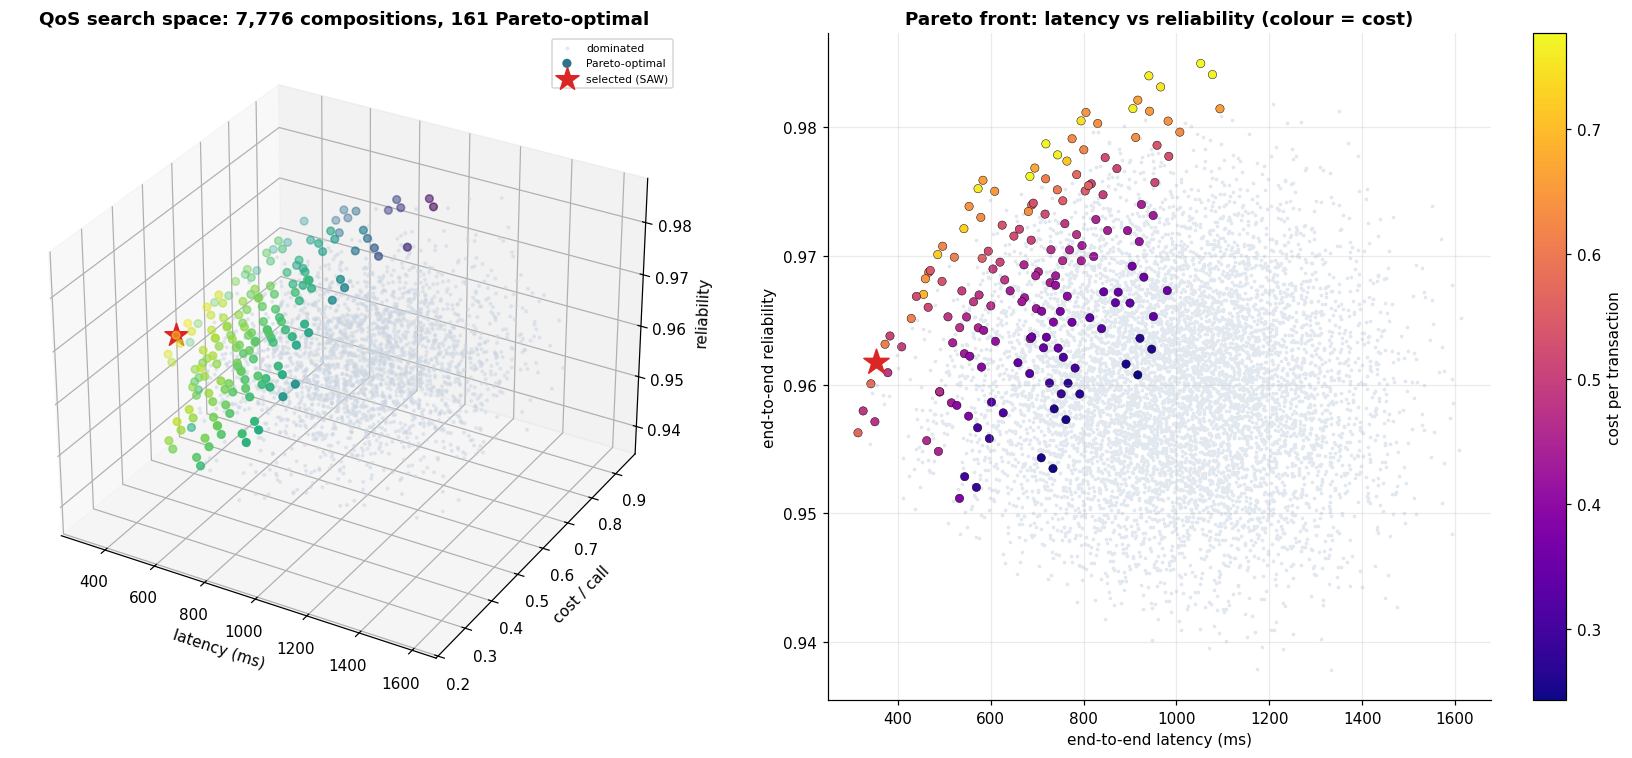

Selected binding: {'KYC-Verify': 'Provider-4', 'FraudScore': 'Provider-2', 'PaymentRoute': 'Provider-2', 'SMS-Notify': 'Provider-1', 'Receipt-Store': 'Provider-3'}
latency=353 ms | cost=0.489 | reliability=96.1769%


In [8]:
# ============ CELL 7: Select concrete providers for each abstract service ============
ABSTRACT = ["KYC-Verify","FraudScore","PaymentRoute","SMS-Notify","Receipt-Store"]
K = 6   # 6 candidate providers each -> 6^5 = 7,776 candidate compositions
cand = {a: pd.DataFrame({"lat":rng.uniform(20,400,K), "cost":rng.uniform(0.01,0.2,K),
                         "rel":rng.uniform(0.985,0.9999,K)}) for a in ABSTRACT}
rows = []
for combo in product(range(K), repeat=len(ABSTRACT)):
    lat  = sum(cand[a].lat[c]  for a,c in zip(ABSTRACT,combo))   # sequential workflow: additive
    cost = sum(cand[a].cost[c] for a,c in zip(ABSTRACT,combo))
    rel  = np.prod([cand[a].rel[c] for a,c in zip(ABSTRACT,combo)])  # multiplicative
    rows.append((combo, lat, cost, rel))
Q = pd.DataFrame(rows, columns=["combo","latency","cost","reliability"])

def pareto(df):   # minimise latency, cost; maximise reliability
    X = np.c_[df.latency, df.cost, -df.reliability]
    eff = np.ones(len(X), bool)
    for i in range(len(X)):
        if eff[i]:
            dom = np.all(X <= X[i], 1) & np.any(X < X[i], 1)
            if dom.any(): eff[i] = False
    return eff
Q["pareto"] = pareto(Q)
w = np.array([0.4,0.3,0.3])   # SAW utility weights
norm = lambda s, inv=False: (s.max()-s)/(s.max()-s.min()) if not inv else (s-s.min())/(s.max()-s.min())
Q["utility"] = w[0]*norm(Q.latency) + w[1]*norm(Q.cost) + w[2]*norm(Q.reliability, True)
best = Q.loc[Q.utility.idxmax()]

fig = plt.figure(figsize=(16,7))
ax = fig.add_subplot(1,2,1, projection="3d")
d = Q[~Q.pareto].sample(2500, random_state=1)
ax.scatter(d.latency, d.cost, d.reliability, s=3, c="#cbd5e1", alpha=0.4, label="dominated")
p = Q[Q.pareto]
ax.scatter(p.latency, p.cost, p.reliability, s=25, c=p.utility, cmap="viridis", label="Pareto-optimal")
ax.scatter([best.latency],[best.cost],[best.reliability], s=250, marker="*", c=PAL["red"], label="selected (SAW)")
ax.set(xlabel="latency (ms)", ylabel="cost / call", zlabel="reliability"); ax.legend(fontsize=7)
ax.set_title(f"QoS search space: {len(Q):,} compositions, {Q.pareto.sum()} Pareto-optimal")

ax = fig.add_subplot(1,2,2)
ax.scatter(Q.latency, Q.reliability, s=2, c="#e2e8f0")
sc = ax.scatter(p.latency, p.reliability, c=p.cost, cmap="plasma", s=30, edgecolor="k", lw=0.3)
ax.scatter(best.latency, best.reliability, marker="*", s=300, c=PAL["red"])
plt.colorbar(sc, ax=ax, label="cost per transaction")
ax.set(xlabel="end-to-end latency (ms)", ylabel="end-to-end reliability", title="Pareto front: latency vs reliability (colour = cost)")
plt.tight_layout(); plt.show()
print("Selected binding:", {a: f"Provider-{c+1}" for a,c in zip(ABSTRACT, best.combo)})
print(f"latency={best.latency:.0f} ms | cost={best.cost:.3f} | reliability={best.reliability:.4%}")

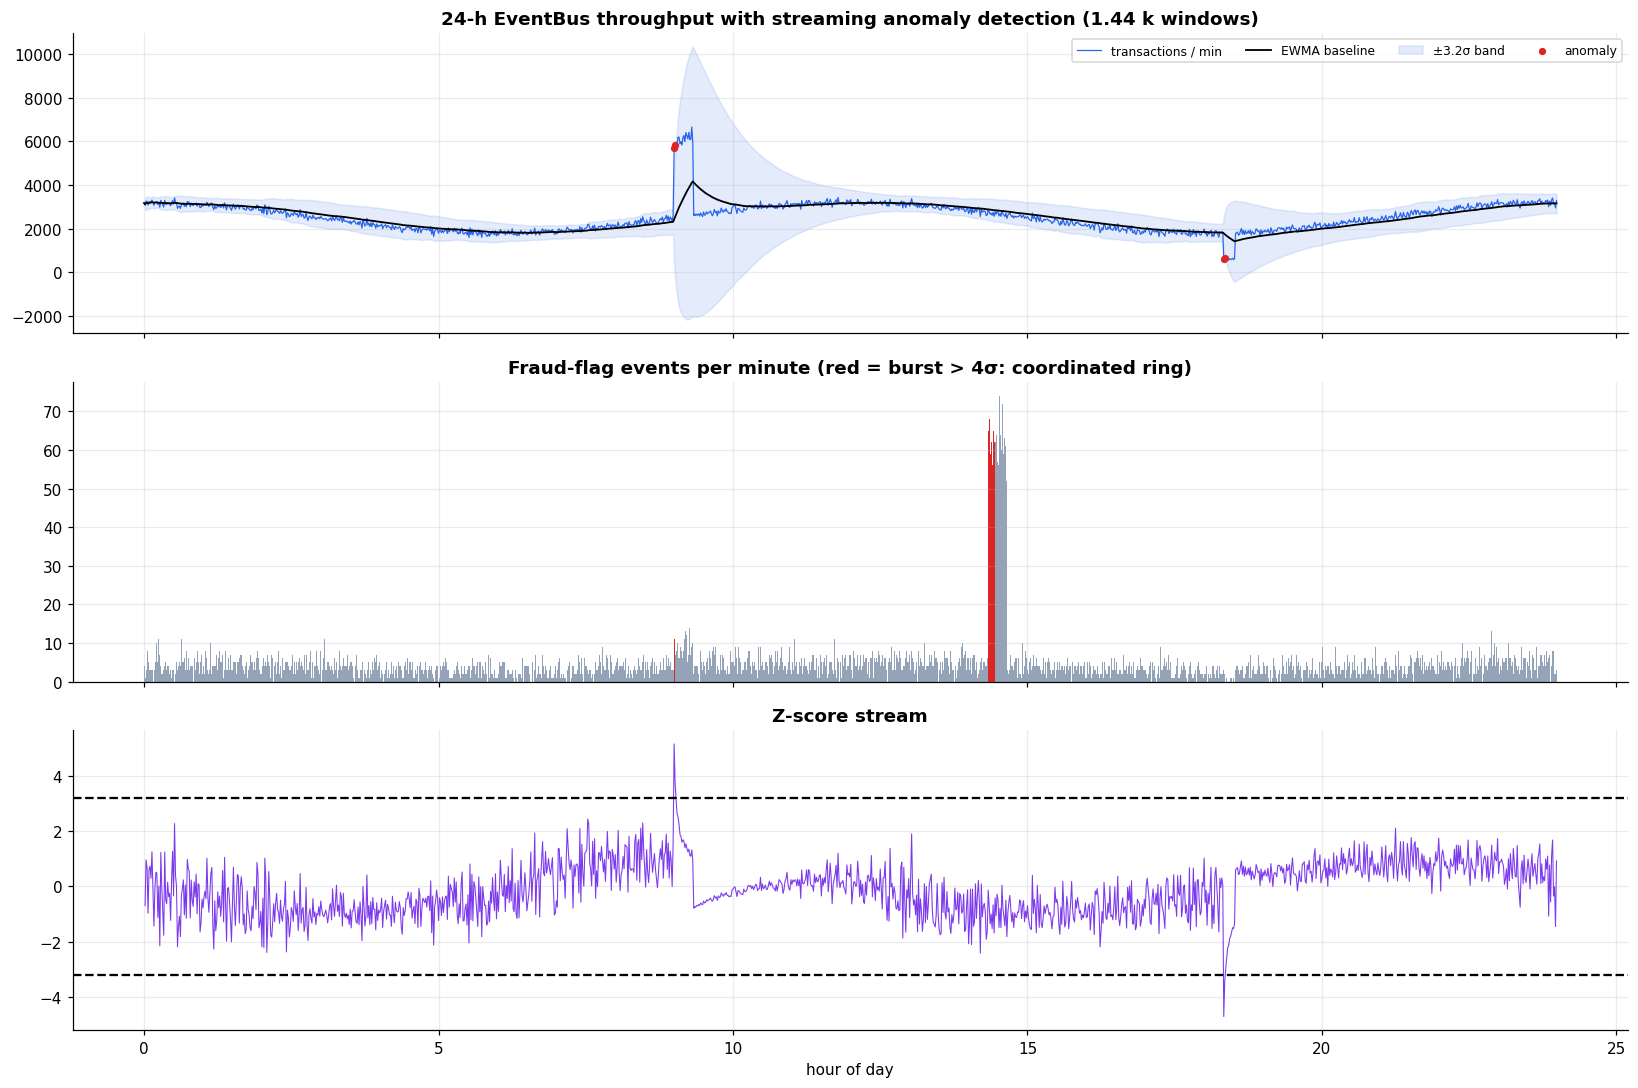

Events processed: 3,649,101 | anomaly windows: 4 | fraud bursts: 8


In [9]:
# ============ CELL 8: Streaming anomaly detection over EventBus telemetry ============
minutes = 60*24
tm = np.arange(minutes)
tps = 1800 + 1400*np.sin((tm/minutes)*2*np.pi - np.pi/2)**2 + rng.normal(0,90,minutes)
tps[540:560] *= 2.4          # flash-sale surge
tps[1100:1112] *= 0.35       # partial outage
fraud = rng.poisson(tps*0.0015); fraud[860:880] += rng.poisson(60, 20)   # coordinated fraud ring

s = pd.Series(tps); mu = s.ewm(span=60).mean(); sd = s.ewm(span=60).std()
z = (s - mu)/sd
anom = np.abs(z) > 3.2
fs = pd.Series(fraud); fz = (fs - fs.rolling(120,min_periods=30).median())/fs.rolling(120,min_periods=30).std()

fig, axes = plt.subplots(3,1, figsize=(15,10), sharex=True)
axes[0].plot(tm/60, tps, color=PAL["blue"], lw=0.8, label="transactions / min")
axes[0].plot(tm/60, mu, color="k", lw=1.2, label="EWMA baseline")
axes[0].fill_between(tm/60, mu-3.2*sd, mu+3.2*sd, color=PAL["blue"], alpha=0.12, label="±3.2σ band")
axes[0].scatter(tm[anom]/60, tps[anom], color=PAL["red"], s=14, zorder=5, label="anomaly")
axes[0].set_title("24-h EventBus throughput with streaming anomaly detection (1.44 k windows)"); axes[0].legend(fontsize=8, ncol=4)
axes[1].bar(tm/60, fraud, width=1/60, color=np.where(fz>4, PAL["red"], "#94a3b8"))
axes[1].set_title("Fraud-flag events per minute (red = burst > 4σ: coordinated ring)")
axes[2].plot(tm/60, z, color=PAL["violet"], lw=0.7); axes[2].axhline(3.2, ls="--", c="k"); axes[2].axhline(-3.2, ls="--", c="k")
axes[2].set(title="Z-score stream", xlabel="hour of day")
plt.tight_layout(); plt.show()
print(f"Events processed: {int(tps.sum()):,} | anomaly windows: {anom.sum()} | fraud bursts: {(fz>4).sum()}")

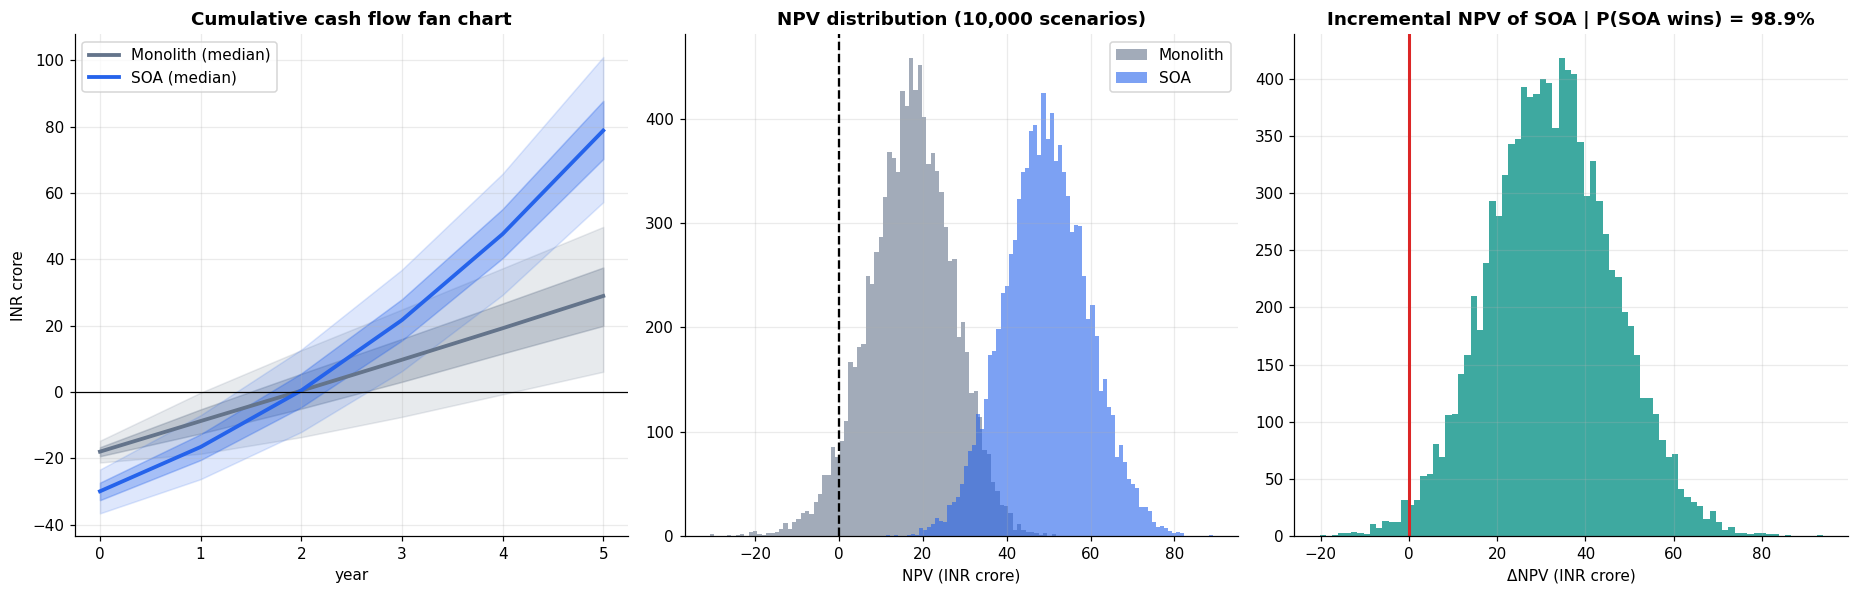

          Median NPV (cr)  P(NPV<0)  Median payback (yr)  5-yr ROI %
Monolith            17.39      0.05                  2.0      160.02
SOA                 49.26      0.00                  2.0      262.80


In [10]:
# ============ CELL 9: Monolith vs SOA economic model, 10,000 scenarios ============
SIMS, YEARS, r = 10_000, 5, 0.10   # 10% discount rate (INR crore)
def mc(arch):
    if arch == "Monolith":
        capex = rng.normal(18, 2, SIMS)
        opex  = rng.normal(9, 1, (SIMS, YEARS)) * (1.12 ** np.arange(YEARS))     # tech-debt growth
        rev   = rng.normal(22, 4, (SIMS, YEARS)) * (1.06 ** np.arange(YEARS))
        outage= rng.poisson(3, (SIMS, YEARS)) * rng.lognormal(np.log(1.2), .5, (SIMS, YEARS))
    else:
        capex = rng.normal(30, 4, SIMS)                                            # higher upfront
        opex  = rng.normal(8, 1, (SIMS, YEARS)) * (0.95 ** np.arange(YEARS))     # reuse savings
        rev   = rng.normal(22, 4, (SIMS, YEARS)) * (1.15 ** np.arange(YEARS))     # faster time-to-market
        outage= rng.poisson(1, (SIMS, YEARS)) * rng.lognormal(np.log(0.6), .5, (SIMS, YEARS))
    cf = rev - opex - outage
    disc = (1+r) ** -np.arange(1, YEARS+1)
    return -capex + (cf*disc).sum(1), np.c_[-capex, cf].cumsum(1)
npv_m, cum_m = mc("Monolith"); npv_s, cum_s = mc("SOA")

fig, axes = plt.subplots(1,3, figsize=(17,5.5))
ax = axes[0]
for cum, c, lbl in [(cum_m, PAL["grey"], "Monolith"), (cum_s, PAL["blue"], "SOA")]:
    q = np.percentile(cum, [5,25,50,75,95], axis=0); x = np.arange(YEARS+1)
    ax.fill_between(x, q[0], q[4], color=c, alpha=0.15); ax.fill_between(x, q[1], q[3], color=c, alpha=0.3)
    ax.plot(x, q[2], color=c, lw=2.5, label=f"{lbl} (median)")
ax.axhline(0, color="k", lw=0.8); ax.set(title="Cumulative cash flow fan chart", xlabel="year", ylabel="INR crore"); ax.legend()

ax = axes[1]
ax.hist(npv_m, bins=80, alpha=0.6, color=PAL["grey"], label="Monolith")
ax.hist(npv_s, bins=80, alpha=0.6, color=PAL["blue"], label="SOA")
ax.axvline(0, color="k", ls="--"); ax.set(title="NPV distribution (10,000 scenarios)", xlabel="NPV (INR crore)"); ax.legend()

ax = axes[2]
delta = npv_s - npv_m
ax.hist(delta, bins=80, color=PAL["teal"], alpha=0.8)
ax.axvline(0, color=PAL["red"], lw=2)
ax.set(title=f"Incremental NPV of SOA | P(SOA wins) = {(delta>0).mean():.1%}", xlabel="ΔNPV (INR crore)")
plt.tight_layout(); plt.show()

payback = lambda cum: np.where((cum>0).any(1), (cum>0).argmax(1), np.nan)
print(pd.DataFrame({
  "Median NPV (cr)": [np.median(npv_m), np.median(npv_s)],
  "P(NPV<0)":        [(npv_m<0).mean(), (npv_s<0).mean()],
  "Median payback (yr)": [np.nanmedian(payback(cum_m)), np.nanmedian(payback(cum_s))],
  "5-yr ROI %":      [np.median((cum_m[:,-1])/np.abs(cum_m[:,0])*100), np.median((cum_s[:,-1])/np.abs(cum_s[:,0])*100)],
}, index=["Monolith","SOA"]).round(2))

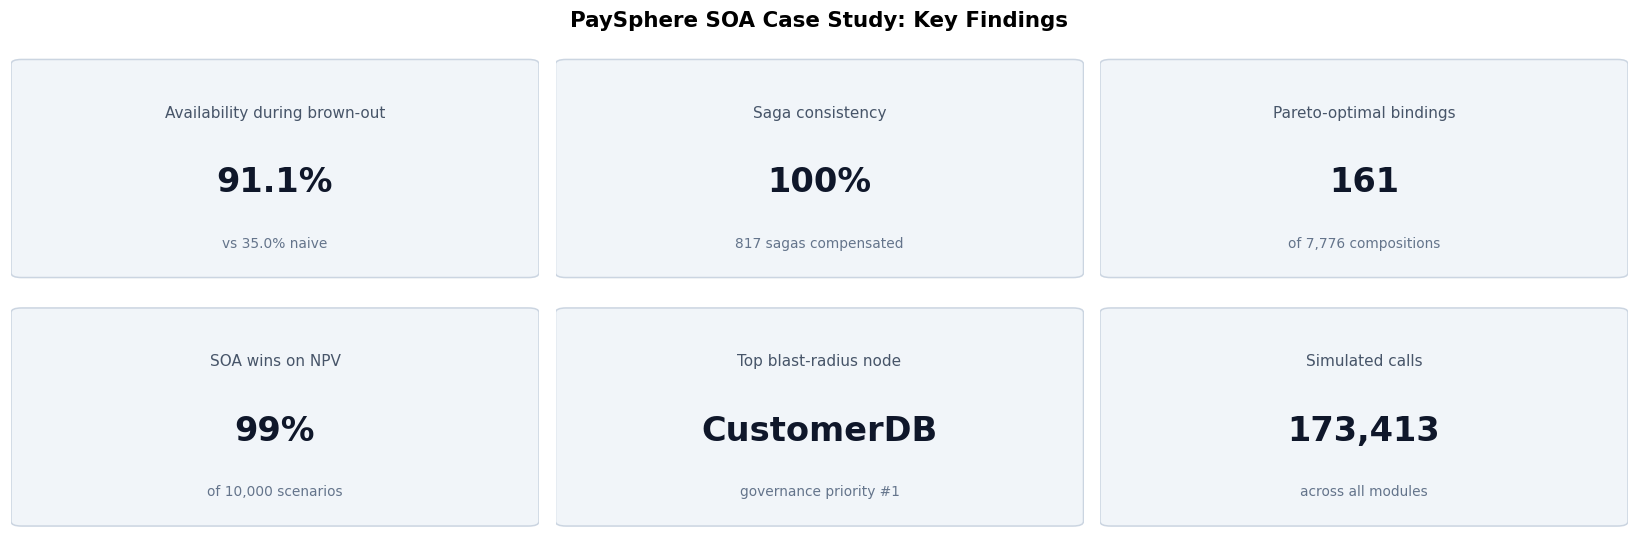

In [11]:
# ============ CELL 10: One-page KPI summary for the report ============
succ = SIM.groupby("strategy").ok.mean().loc[strategies]*100
kpis = [
    ("Availability during brown-out", f"{SIM[(SIM.strategy==strategies[2])&(SIM.t.between(300,480))].ok.mean():.1%}",
     f"vs {SIM[(SIM.strategy==strategies[0])&(SIM.t.between(300,480))].ok.mean():.1%} naive"),
    ("Saga consistency", "100%", f"{(O.outcome!='COMMITTED').sum()} sagas compensated"),
    ("Pareto-optimal bindings", f"{Q.pareto.sum()}", f"of {len(Q):,} compositions"),
    ("SOA wins on NPV", f"{(delta>0).mean():.0%}", "of 10,000 scenarios"),
    ("Top blast-radius node", risk.nlargest(1,'blast').service.iloc[0], "governance priority #1"),
    ("Simulated calls", f"{3*N + len(L) + len(E):,}", "across all modules"),
]
fig, axes = plt.subplots(2,3, figsize=(15,5))
for ax, (title, val, sub) in zip(axes.flat, kpis):
    ax.axis("off"); ax.add_patch(mpatches.FancyBboxPatch((0.02,0.05),0.96,0.9, boxstyle="round,pad=0.02",
                                  fc="#f1f5f9", ec="#cbd5e1", transform=ax.transAxes))
    ax.text(0.5,0.72,title,ha="center",fontsize=10,color="#475569",transform=ax.transAxes)
    ax.text(0.5,0.40,val,ha="center",fontsize=22,fontweight="bold",color="#0f172a",transform=ax.transAxes)
    ax.text(0.5,0.16,sub,ha="center",fontsize=9,color="#64748b",transform=ax.transAxes)
plt.suptitle("PaySphere SOA Case Study: Key Findings", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()